# Les électeurs sanctionnent-ils vraiment les maires visés par une affaire judiciaire ?

*Projet personnel de data science.*

Ce notebook fait la **synthèse** du projet : il reprend la démarche et les
résultats en appelant le code de `src/`. Chaque
étape est détaillée dans un notebook dédié :

| notebook | contenu |
|---|---|
| `01_exploration` | diagnostic de chaque source (dimensions, manquants, doublons, couverture) |
| `02_panel_sortants` | le comportement électoral d'un maire sortant « ordinaire » |
| `03_affaires` | les affaires judiciaires, leur rattachement aux sortants, comparaisons à taille égale |
| `04_modelisation` | régressions, appariement sur score de propension, bord politique, stade de l'affaire, robustesse |

Il s'exécute de bout en bout depuis un dépôt vierge : les données manquantes sont
téléchargées depuis leurs sources publiques (environ 550 Mo au premier lancement, 2 Go sur disque une fois décompressés).

## Résumé des résultats

On rapproche **741 affaires judiciaires** recensées par deux bases citoyennes (Casier Politique, Poligraph) des **maires sortants** des municipales de 2020 et 2026 (près de 44 000 communes x élection). Après élimination des homonymes et des maires partis en cours de mandat, **75 sortants** avaient une affaire connue au moment du vote, dont 40 révélée pendant le mandat qui s'achevait.

**Résultat principal : aucune sanction électorale robuste n'est détectable.** Les sortants visés par une affaire se représentent, conservent leur score et gagnent aussi souvent que des sortants comparables. Deux pièges expliquent les résultats trompeurs des comparaisons naïves : le **retour vers la moyenne** (ces maires avaient été moins bien élus la fois précédente) et la **notoriété** (les élus assez connus pour figurer dans nos sources bénéficient d'une prime électorale). À notoriété égale, une affaire révélée pendant le mandat réduirait la probabilité de victoire d'environ 30 points, mais ce résultat est à la limite de la significativité et repose sur quelques dizaines de cas.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent  # notebook lancé depuis notebooks/
sys.path.insert(0, str(ROOT / "src"))
import affaires as A  # noqa: E402
import analyse as An  # noqa: E402
import graphiques as G  # noqa: E402
import modeles as M  # noqa: E402
import panel as P  # noqa: E402

pd.set_option("display.width", 200)
G.style()

## 1. Question et stratégie

La science politique décrit un **avantage du sortant** : le maire qui se représente
gagne le plus souvent. Une affaire judiciaire (enquête, mise en examen,
condamnation) devrait l'entamer si les électeurs sanctionnent les manquements à la
probité. On compare donc les maires sortants visés par une affaire **connue au
moment du vote** aux autres sortants, aux municipales de **2020** et de **2026**.

Trois résultats sont mesurés : le sortant **se représente-t-il** ? Comment évolue
son **score** au 1er tour par rapport à l'élection précédente ? Sa liste
**gagne-t-elle** ?

Deux difficultés guident la démarche :

- les sortants visés par une affaire ne sont pas des maires comme les autres (grandes
  villes, figures nationales) : il faut comparer à caractéristiques égales ;
- les sources d'affaires ne recensent que des élus connus : il faut séparer l'effet
  de l'affaire de celui de la **notoriété**.

## 2. Données

| source | producteur | usage |
|---|---|---|
| résultats et candidatures des municipales 2014, 2020, 2026 | ministère de l'Intérieur (data.gouv.fr) | score, victoire, candidature du sortant |
| maires sortants 2026, Répertoire national des élus | ministère de l'Intérieur | identité du sortant, contrôle des appariements |
| Code officiel géographique 2026, contours des communes | INSEE, Etalab | fusions de communes, carte |
| recensement 2017 et 2023, revenus Filosofi | INSEE (API Melodi) | contexte socio-économique |
| présidentielles 2017 et 2022 | ministère de l'Intérieur | contexte politique local |
| affaires judiciaires | Casier Politique (Wikipédia), Poligraph | traitement : affaire connue au vote |

Il n'existe pas de base officielle nominative des procédures visant des élus. Les deux
bases d'affaires sont des initiatives citoyennes : on en utilise un **instantané
daté** (`data/snapshots/`), pour que les résultats ne changent pas au gré de leurs
mises à jour.

**Chaîne de traitement** (`src/`) : téléchargement (`scripts/download_data.py`) →
nettoyage et codes INSEE harmonisés (`load.py`) → panel « maire sortant x élection »
(`panel.py`) → rattachement des affaires aux sortants (`affaires.py`) → contexte
communal (`covariables.py`) → modèles (`analyse.py`, `modeles.py`).

In [2]:
panel_sortants = P.load_panel()
personnes, toutes = A.toutes_affaires()
couples = A.apparier_sortants(panel_sortants, personnes)
panel, aff = A.build()
panel = panel[~panel.perimetre_modifie].copy()
d = M.table_modele()

pd.Series({
    "communes x élection dans le panel": len(panel),
    "affaires recensées (deux sources)": len(toutes),
    "personnalités recensées": personnes.personne_id.nunique(),
    "rapprochements personnalité-sortant confirmés": int(couples.confirme.sum()),
    "  rejetés : homonymes": int((couples.motif_rejet == "homonyme probable").sum()),
    "  rejetés : plus maire au scrutin": int((couples.motif_rejet == "plus maire au scrutin").sum()),
    "sortants avec une affaire connue au vote": int(panel.affaire_connue.sum()),
    "  dont révélée pendant le mandat": int(panel.affaire_mandat.sum()),
    "échantillon des modèles (têtes de liste, communes disputées)": len(d),
}, name="effectif").to_frame()

,effectif
communes x élection dans le panel,43729
affaires recensées (deux sources),741
personnalités recensées,517
rapprochements personnalité-sortant confirmés,181
rejetés : homonymes,31
rejetés : plus maire au scrutin,18
sortants avec une affaire connue au vote,75
dont révélée pendant le mandat,40
"échantillon des modèles (têtes de liste, communes disputées)",6772


**Lecture.** Le panel couvre presque toutes les communes. Les affaires, elles, ne concernent qu'une petite élite d'élus : 517 personnalités, dont 75 étaient maires sortants avec une affaire connue au moment du vote. Le rapprochement est conservateur. Un sortant n'est rattaché à une affaire que si la date de naissance ou la commune confirme l'identité (31 homonymes écartés), et seulement s'il était encore maire au scrutin (18 maires partis en cours de mandat écartés, la plupart après la loi de 2014 sur le non-cumul des mandats, appliquée en 2017).

## 3. La référence : le maire sortant ordinaire

In [3]:
disputees = panel[panel.n_listes > 1]
pd.DataFrame({
    "se représente (%)": 100 * panel.groupby("annee").sortant_candidat.mean(),
    "conduit sa liste, s'il se représente (%)": 100 * panel[panel.sortant_candidat.fillna(False)]
        .groupby("annee").sortant_tete_liste.mean(),
    "sa liste gagne, communes disputées (%)": 100 * disputees.groupby("annee").liste_sortant_gagnante.mean(),
    "évolution médiane du score (points)": d.groupby("annee").delta_pct_voix_exp.median(),
}).T.astype(float).round(1)

annee,2020,2026
se représente (%),66.8,73.5
"conduit sa liste, s'il se représente (%)",89.2,86.9
"sa liste gagne, communes disputées (%)",74.0,70.1
évolution médiane du score (points),-1.7,-6.3


**Lecture.** Un maire sortant ordinaire se représente deux fois sur trois en 2020 et trois fois sur quatre en 2026. Quand il y a compétition, sa liste gagne 7 fois sur 10 : c'est l'**avantage du sortant**. Son score recule en médiane d'une élection à l'autre (-1,7 point en 2020, -6,3 en 2026), et cette évolution est très dispersée (notebook 02) : c'est le bruit de fond dans lequel il faut détecter une éventuelle sanction.

## 4. Les sortants visés par une affaire

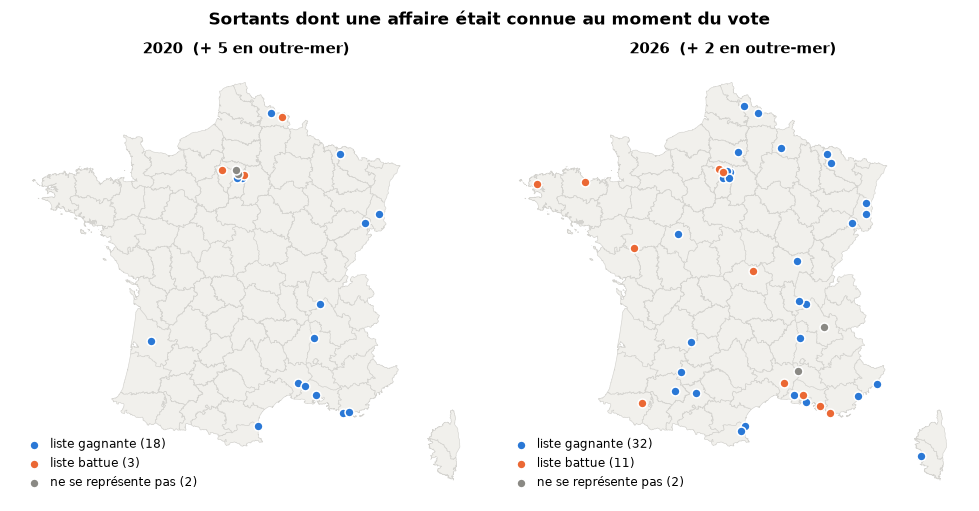

,effectif,inscrits,score_precedent,evolution_score,victoire
groupe,,,,,
affaire connue au vote,57,27444.0,52.04,-1.11,0.81
autres sortants,6669,2586.0,62.10,-7.31,0.74
"personnalité, affaire future",46,25936.5,50.13,1.04,0.93


In [4]:
G.carte_affaires(panel)
plt.show()

groupe = np.select([d.affaire_connue == 1, d.personnalite_affaires == 1],
                   ["affaire connue au vote", "personnalité, affaire future"], "autres sortants")
(d.assign(groupe=groupe).groupby("groupe")
 .agg(effectif=("code_insee", "size"), inscrits=("inscrits", "median"),
      score_precedent=("pct_voix_exp_prec", "mean"), evolution_score=("delta_pct_voix_exp", "mean"),
      victoire=("gagne", "mean"))
 .round(2))

**Lecture.** Les sortants visés par une affaire dirigent des villes dix fois plus peuplées que la médiane, sont concentrés en Île-de-France et sur le pourtour méditerranéen, et gagnent 4 fois sur 5. Les personnalités dont l'affaire n'éclatera qu'après le vote leur ressemblent beaucoup (taille, score précédent), mais font encore mieux (93 % de victoires). C'est le point de comparaison le plus juste pour isoler l'effet de l'affaire.

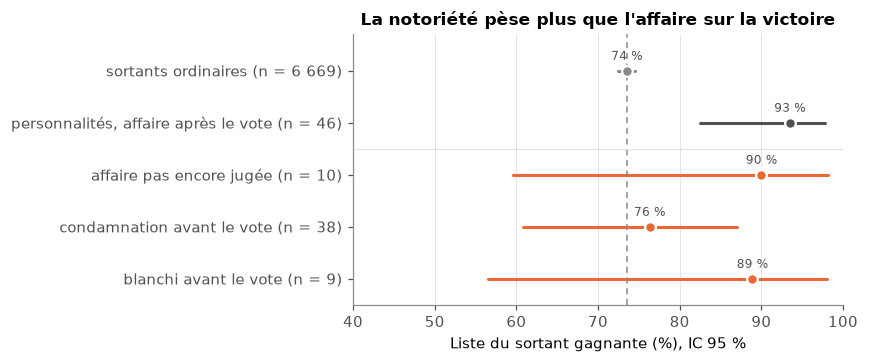

In [5]:
G.victoire_par_groupe(d)
plt.show()

**Lecture.** Quand il y a compétition, la liste d'un sortant ordinaire gagne 74 % du temps.
Les personnalités recensées dont l'affaire n'éclatera qu'après le vote gagnent 93 % du
temps : c'est la **prime de notoriété**. Les sortants visés par une affaire se situent
entre les deux. Ceux qui avaient été condamnés avant le vote gagnent 76 % du temps, autant
que des maires ordinaires mais moins que des personnalités comparables. Les intervalles,
très larges pour les groupes d'une dizaine de sortants, invitent à la prudence.

## 5. Résultats : une affaire révélée pendant le mandat coûte-t-elle des voix ?

On estime l'effet d'une affaire **révélée pendant le mandat sortant** (le cas le plus
net : les électeurs la découvrent entre deux scrutins) par quatre approches, toutes
sur le même échantillon de sortants têtes de liste dans des communes disputées.

1. **À taille égale** : écart avec les sortants sans affaire des communes de même
   taille, à la même élection (stratification, IC par bootstrap).
2. **Régression, contre des maires ordinaires** : score précédent, taille, nombre de
   listes, bord politique, contexte socio-économique et présidentiel contrôlés.
3. **Appariement sur le score de propension** : chaque traité est comparé à 5
   sortants sans affaire de profil observable très proche.
4. **Régression, à notoriété égale** : on ajoute l'indicatrice « personnalité
   recensée ». La comparaison se fait alors avec des personnalités dont l'affaire
   n'a éclaté qu'après le vote.

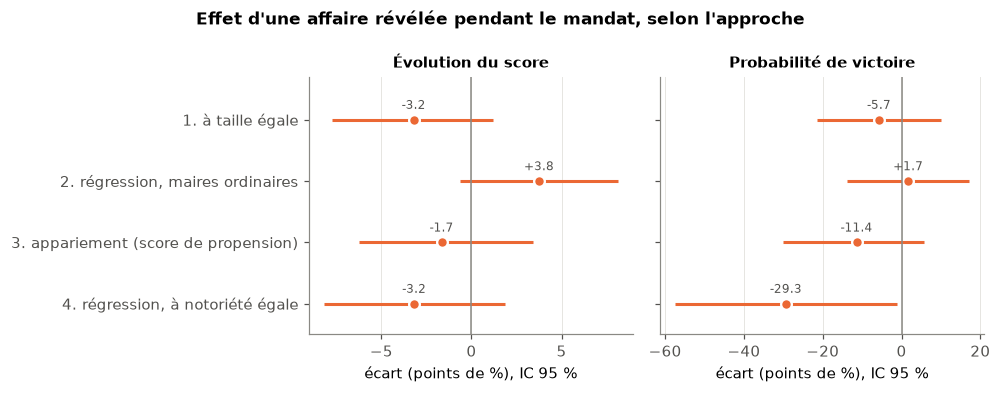

Évolution du score                Probabilité de victoire               
                                                  effet ic_bas ic_haut                   effet ic_bas ic_haut
1. à taille égale                                  -3.2   -7.7     1.2                    -5.7  -21.6    10.0
2. régression, maires ordinaires                    3.8   -0.6     8.1                     1.7  -13.8    17.2
3. appariement (score de propension)               -1.7   -6.3     3.4                   -11.4  -30.0     5.7
4. régression, à notoriété égale                   -3.2   -8.2     1.8                   -29.3  -57.5    -1.2

In [6]:
temoin = d.personnalite_affaires == 0
strat = d[(d.affaire_mandat == 1) | temoin]
ordinaires = M.CONTROLES
f_ord = "{y} ~ affaire_mandat + " + ordinaires
f_not = "{y} ~ affaire_mandat + affaire_avant_mandat + personnalite_affaires + " + ordinaires
app = M.appariement(strat.reset_index(drop=True), "affaire_mandat", ["delta_pct_voix_exp", "gagne"])

def ligne(effet, bas, haut, echelle=1):
    return {"effet": effet * echelle, "ic_bas": bas * echelle, "ic_haut": haut * echelle}

def coef(res, echelle=1):
    c = M.coefficients(res).loc["affaire_mandat"]
    return ligne(c.coef, c.ic_bas, c.ic_haut, echelle)

APPROCHES = ["1. à taille égale", "2. régression, maires ordinaires",
             "3. appariement (score de propension)", "4. régression, à notoriété égale"]
score, victoire = {}, {}
s = An.ecart_stratifie(strat, "delta_pct_voix_exp", "affaire_mandat", ["annee", "taille"])
score[APPROCHES[0]] = ligne(s.ecart, s.ic_bas, s.ic_haut)
s = An.ecart_stratifie(strat, "gagne", "affaire_mandat", ["annee", "taille"])
victoire[APPROCHES[0]] = ligne(s.ecart, s.ic_bas, s.ic_haut, 100)
score[APPROCHES[1]] = coef(M.ols(f_ord.format(y="delta_pct_voix_exp"), strat))
victoire[APPROCHES[1]] = coef(M.logit(f_ord.format(y="gagne"), strat), 100)
e = app["effets"]
score[APPROCHES[2]] = ligne(*e.loc["delta_pct_voix_exp", ["effet", "ic_bas", "ic_haut"]])
victoire[APPROCHES[2]] = ligne(*e.loc["gagne", ["effet", "ic_bas", "ic_haut"]], 100)
score[APPROCHES[3]] = coef(M.ols(f_not.format(y="delta_pct_voix_exp"), d))
victoire[APPROCHES[3]] = coef(M.logit(f_not.format(y="gagne"), d), 100)

resultats = pd.concat({"Évolution du score": pd.DataFrame(score).T,
                       "Probabilité de victoire": pd.DataFrame(victoire).T}, axis=1)
G.estimations(resultats, "Effet d'une affaire révélée pendant le mandat, selon l'approche")
plt.show()
resultats.round(1)

**Lecture.**

- **Score.** Aucune approche ne trouve d'effet significatif. Les estimations vont de -3 à +4 points selon le groupe de comparaison, et tous les intervalles contiennent zéro. La perte observée à taille égale (approche 1) disparaît quand on contrôle le score précédent (approche 2) : les sortants visés par une affaire avaient été moins bien élus la fois précédente, donc avaient moins à perdre.
- **Victoire.** Face à des maires ordinaires, l'affaire ne change rien (approches 1 à 3). À notoriété égale (approche 4), elle réduit la probabilité de victoire d'environ 29 points (IC de -57 à -1). C'est le seul signal de sanction de l'étude : il est fragile (30 traités, porté par 2020) et compensé par la prime de notoriété dont jouissent ces élus.
- **Bord politique, délai, participation.** Les estimations suggèrent une sanction plus forte pour les sortants de gauche que pour ceux de droite, mais l'écart n'est pas significatif (11 sortants de gauche). Ni l'ancienneté de l'affaire ni la participation ne font apparaître d'effet net (notebook 04, sections 4 à 6).
- **Stade de l'affaire.** Aucun stade (affaire pas encore jugée, condamnation, élu blanchi) ne coûte de voix de façon détectable. Une condamnation prononcée avant le vote réduirait la probabilité de victoire d'environ 26 points (p = 0,08), sans écart significatif avec une affaire pas encore jugée (notebook 04, section 8).

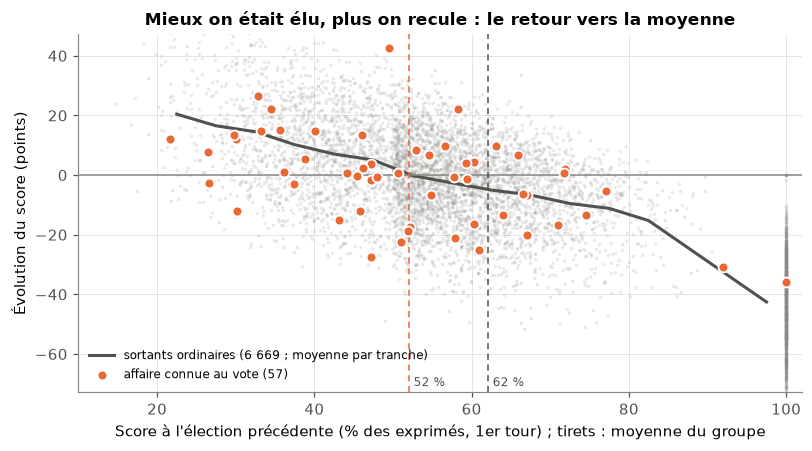

In [7]:
G.retour_moyenne(d)
plt.show()

**Lecture.** Chaque point gris est un sortant ordinaire ; la courbe donne leur évolution
moyenne selon le score obtenu à l'élection précédente. Un sortant élu avec 30 % des voix
progresse en moyenne d'une quinzaine de points, un sortant élu avec 75 % en perd une
dizaine : c'est le **retour vers la moyenne**. Les sortants visés par une affaire (en
orange) avaient été moins bien élus que les autres (52 % contre 62 % en moyenne), mais à
score précédent égal ils se répartissent de part et d'autre de la courbe des sortants
ordinaires : rien ne les en écarte nettement. Toute comparaison qui ignore le score
précédent mélange donc l'effet de l'affaire et celui de ce point de départ.

## 6. Conclusion

**Les électeurs sanctionnent-ils vraiment ?** Avec les données disponibles, pas de manière détectable. Un maire visé par une affaire judiciaire connue au moment du vote ne perd ni plus de voix ni plus souvent sa mairie qu'un maire comparable. Le seul indice de sanction apparaît quand on le compare à des élus aussi connus que lui. La sanction existerait alors, mais serait masquée par l'avantage électoral de la notoriété.

Ce résultat rejoint la littérature, qui trouve des sanctions faibles et inégales. Au Brésil, les électeurs ne sanctionnent les maires corrompus que là où l'information circule, par exemple grâce à une radio locale (Ferraz et Finan, 2008, *Quarterly Journal of Economics*). Une méta-analyse des expériences de terrain trouve un effet moyen de l'information sur la corruption proche de zéro (Incerti, 2020, *American Political Science Review*).

## 7. Limites et prolongements possibles

1. **Couverture des affaires.** Seuls les élus ayant une page Wikipédia ou une fiche Poligraph sont recensés. Les affaires visant des maires de petites communes, de loin les plus nombreuses, échappent à l'étude. Une source exhaustive (presse quotidienne régionale, décisions de justice via l'API Judilibre) permettrait d'élargir l'échantillon.
2. **Datation.** La date de la procédure ou du verdict est postérieure à la révélation médiatique. Dater la première mention dans la presse affinerait la distinction « connue / pas connue au vote ».
3. **Sortants 2020.** Il n'existe pas de liste officielle : le sortant est approché par la tête de la liste gagnante de 2014. Les départs en cours de mandat ne sont corrigés que pour les personnalités recensées.
4. **Puissance statistique.** Avec 30 à 60 traités, une sanction de quelques points passerait inaperçue : l'absence de preuve n'est pas la preuve de l'absence.
5. **Causalité.** Même à caractéristiques et notoriété égales, les affaires ne sont pas attribuées au hasard. Un maire sous pression judiciaire peut par exemple renoncer à se représenter, et sortir ainsi de l'échantillon des têtes de liste.